# 03 Moving block bootstrap

Owner: Deng Shenbojia (A4, A5).

Implementation details, main result at l = 14, block-length sensitivity, side-by-side CIs.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

from src.data import load_daily
from src.strategy import build_series
from src.classical import t_test_mean
from src.bootstrap import mbb_ci, mbb_test

rng = np.random.default_rng(config.SEED)

 ## 1. How the block bootstrap works


## 2. Main result (block length 14)

In [2]:
d = build_series(load_daily())["d"].to_numpy()  # daily excess return of the rule, 2,557 days
L = config.BLOCK_LENGTH  # pre-registered block length: round(2557 ** (1/3)) = 14

ci = mbb_ci(d, L)  # bootstrap SE and 95% intervals (B = 9,999, seed 607)
test = mbb_test(d, L)  # p-value for H0: mean of d = 0

main = pd.DataFrame([{
    "L": L,
    "B": ci["B"],
    "mean_d": ci["mean"],
    "boot_se": ci["se"],
    "ci_lo": ci["pct_lo"],  # percentile interval (main result)
    "ci_hi": ci["pct_hi"],
    "p": test["p"],
}])
config.TAB_DIR.mkdir(parents=True, exist_ok=True)  # outputs/tables/
main.to_csv(config.TAB_DIR / "03_main_result.csv", index=False)  # saved for README and slides
print(main.round(6).to_string(index=False))
print("95% CI contains 0:", ci["pct_lo"] < 0 < ci["pct_hi"])

 L    B    mean_d  boot_se     ci_lo    ci_hi      p
14 9999 -0.000208 0.000416 -0.001012 0.000617 0.6177
95% CI contains 0: True


With a block length of 14, the average daily excess return is −0.000208, and the 95% confidence interval is [−0.00101, 0.00062], p = 0.62.  
This means the interval includes zero, and the p-value is much greater than 0.05, so we cannot conclude that the rule's average daily return differs from buy-and-hold.

## 3. Sensitivity to the block length

 L  boot_se     ci_lo    ci_hi      p
 1 0.000476 -0.001132 0.000740 0.6613
 5 0.000445 -0.001058 0.000682 0.6380
10 0.000428 -0.001015 0.000662 0.6239
14 0.000416 -0.001012 0.000617 0.6177
20 0.000403 -0.000959 0.000625 0.6037
40 0.000377 -0.000914 0.000572 0.5785
t-test SE: 0.000475


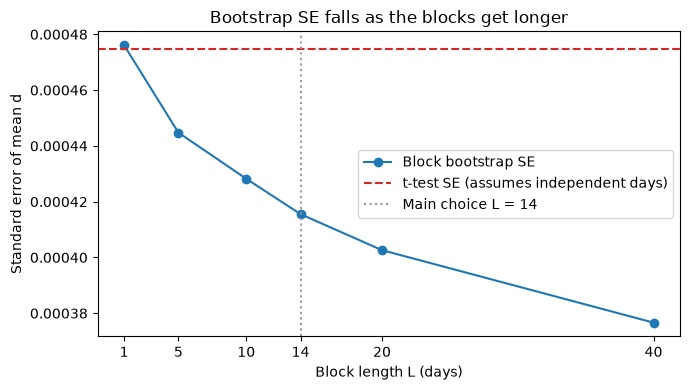

In [3]:
t_res = t_test_mean(d)  # Ma's t-test: reference line for the plot

rows = []
for L_i in config.BLOCK_GRID:  # [1, 5, 10, 14, 20, 40], fixed in config.py
    r = mbb_ci(d, L_i)  # same seed for every L, so only the block length changes
    rows.append({"L": L_i, "boot_se": r["se"], "ci_lo": r["pct_lo"], "ci_hi": r["pct_hi"], "p": mbb_test(d, L_i)["p"]})
sens = pd.DataFrame(rows)
sens.to_csv(config.TAB_DIR / "03_block_length_sensitivity.csv", index=False)
print(sens.round(6).to_string(index=False))
print("t-test SE:", round(t_res["se"], 6))

config.FIG_DIR.mkdir(parents=True, exist_ok=True)  # outputs/figures/
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sens["L"], sens["boot_se"], marker="o", color="C0", label="Block bootstrap SE")
ax.axhline(t_res["se"], color="C3", linestyle="--", label="t-test SE (assumes independent days)")
ax.axvline(L, color="0.6", linestyle=":", label="Main choice L = 14")
ax.set_xticks(config.BLOCK_GRID)
ax.set_xlabel("Block length L (days)")
ax.set_ylabel("Standard error of mean d")
ax.set_title("Bootstrap SE falls as the blocks get longer")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIG_DIR / "03_se_by_block_length.png", dpi=150)
plt.show()

When L = 1, the bootstrap standard error (SE) is almost identical to that of the t-test; as the block length increases, the SE decreases, being about 20% smaller than the t-test when L = 40. This implies that longer blocks preserve more of the "today-and-yesterday" relationship. Because the first-order autocorrelation of d is negative (−0.11), positive and negative days partly cancel out, so the t-test, which ignores this, overestimates the uncertainty. Additionally, all six intervals for different block lengths include zero, with p-values above 0.58, indicating that the conclusion is robust to the choice of block length.

## 4. Bootstrap distribution of the mean

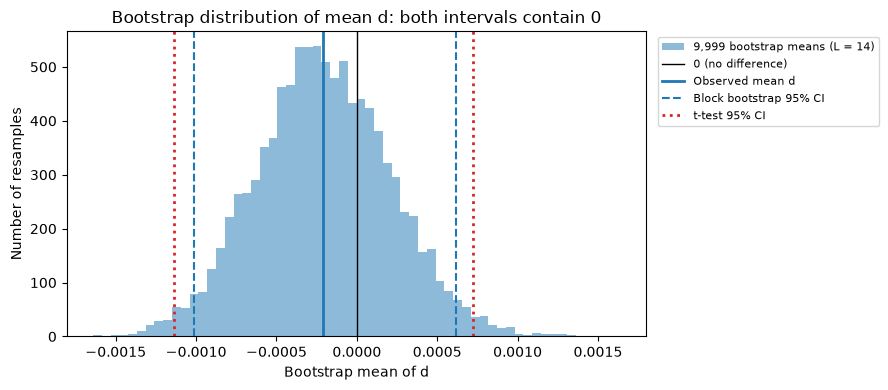

bootstrap CI width: 0.001629 | t-test CI width: 0.001862


In [4]:
from src.bootstrap import mbb_means

boot = mbb_means(d, L)  # the same 9,999 means that mbb_ci(d, 14) used (same seed 607)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(boot, bins=60, color="C0", alpha=0.5, label="9,999 bootstrap means (L = 14)")
ax.axvline(0, color="black", lw=1, label="0 (no difference)")
ax.axvline(ci["mean"], color="C0", lw=2, label="Observed mean d")
ax.axvline(ci["pct_lo"], color="C0", linestyle="--", label="Block bootstrap 95% CI")
ax.axvline(ci["pct_hi"], color="C0", linestyle="--")
ax.axvline(t_res["t_lo"], color="C3", linestyle=":", lw=2, label="t-test 95% CI")
ax.axvline(t_res["t_hi"], color="C3", linestyle=":", lw=2)
ax.set_xlabel("Bootstrap mean of d")
ax.set_ylabel("Number of resamples")
ax.set_title("Bootstrap distribution of mean d: both intervals contain 0")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))  # legend outside, so it hides no line
fig.tight_layout()
fig.savefig(config.FIG_DIR / "03_bootstrap_hist.png", dpi=150)
plt.show()
print("bootstrap CI width:", round(ci["pct_hi"] - ci["pct_lo"], 6), "| t-test CI width:", round(t_res["t_hi"] - t_res["t_lo"], 6))

The 9,999 bootstrap means are approximately bell-shaped, centered around the observed mean; zero lies in the middle of the distribution, far from both tails. The blue bootstrap interval is narrower than the red t-test interval (width 0.00163 vs. 0.00186, about 12% narrower).  
This indicates that both methods include zero within their intervals, leading to consistent conclusions: the rule and buy-and-hold strategies cannot be distinguished. The distribution appears nearly normal, suggesting that the t-test's normal approximation is valid for a sample size of 2,557 days; the difference between the two methods arises from the standard error (autocorrelation), not from the shape of the distribution.

## 5. Side by side: t-test vs block bootstrap

In [5]:
from src.classical import variance_factor

side = pd.DataFrame([
    {"method": "t-test (independent days)", "mean_d": t_res["mean"], "se": t_res["se"],
     "ci_lo": t_res["t_lo"], "ci_hi": t_res["t_hi"], "p": t_res["p"]},
    {"method": "Block bootstrap (L = 14)", "mean_d": ci["mean"], "se": ci["se"],
     "ci_lo": ci["pct_lo"], "ci_hi": ci["pct_hi"], "p": test["p"]},
])
side["ci_width"] = side["ci_hi"] - side["ci_lo"]
side.to_csv(config.TAB_DIR / "03_side_by_side.csv", index=False)
print(side.round(6).to_string(index=False))

vf = variance_factor(d, L)  # Ma's formula: 1 + 2 x (weighted autocorrelations of d up to lag 14)
print("\nMa's variance factor (Bartlett, K = 14):", round(vf, 3))
print("SE predicted by the formula:", round(t_res["se"] * np.sqrt(vf), 6), "| bootstrap SE:", round(ci["se"], 6))
print("bootstrap SE / t-test SE:", round(ci["se"] / t_res["se"], 3), "| sqrt(factor):", round(np.sqrt(vf), 3))

                   method    mean_d       se     ci_lo    ci_hi        p  ci_width
t-test (independent days) -0.000208 0.000475 -0.001139 0.000723 0.661586  0.001862
 Block bootstrap (L = 14) -0.000208 0.000416 -0.001012 0.000617 0.617700  0.001629

Ma's variance factor (Bartlett, K = 14): 0.735
SE predicted by the formula: 0.000407 | bootstrap SE: 0.000416
bootstrap SE / t-test SE: 0.875 | sqrt(factor): 0.857


The means of the two methods are the same, but the bootstrap standard error (SE) is about 12% smaller (0.000416 vs. 0.000475), and the confidence interval is proportionally narrower as well. Both p-values exceed 0.6, and both intervals include zero.

Why it's narrower: The first-order autocorrelation of d is negative, so the term in parentheses in Ma's formula (notebook 02) equals 0.735, which is less than 1. According to the formula, the true SE should be approximately √0.735 ≈ 0.86 times that of the t-test, or about 0.000407—very close to the bootstrap estimate of 0.000416. That two entirely different methods yield nearly identical results confirms that the explanation "the interval narrows due to negative autocorrelation" is supports.

Conclusion: The t-test here is somewhat conservative (producing wider intervals), but after correction, the conclusion remains unchanged: there is no significant difference between the rule and buy-and-hold strategies.